# E-commerce Product Analytics — Retention & Cohort Analysis

## 1. Business Questions

This analysis focuses on user retention and cohort behavior and answers the following questions:

- Do users return to the product after their first activity?
- How does retention change over time?
- How does retention differ across user cohorts?
- Are there noticeable differences in retention between earlier and later cohorts?
- What patterns require further investigation?

## 2. Retention Metrics

- **Cohort** — group of users whose first event falls in the same calendar month.
- **Day-N Retention (Exact-Day)** — percentage of eligible users who are active exactly N days after their first event.
- **Bracket Retention** — percentage of eligible users who are active at least once during a time interval after their first event (Day 1–7, 8–14, 15–30, 31+).
- **D30 Unbounded Retention** — percentage of eligible users who are active at least once on Day 30 or later.
- **D30 Churn** — percentage of eligible users with no events on Day 30 or later (100% − D30 Unbounded Retention). D30 Churn is an operational measure based on observed inactivity, not confirmed permanent customer churn.

Definitions follow Amplitude's terminology for N-day, unbounded and bracket retention (see References).

## 3. Data

The analysis uses `events_clean` — the `events` table without the anomalous June–August 2023 sessions identified in `01_engagement.ipynb` (Section 4). Section 4 below shows why the anomaly matters for cohorts.

Main fields:

- `user_id` — identifies the user
- `event_time` — timestamp of the event

**Cohort.** Each user's cohort is the month of their first event in `events_clean`.

**Observation window.** The last day in the data (18 August 2025) is only partly covered, so the data end is the start of that day. Day N of a user is included only if it is fully observed (first event date + N < 18 August 2025); otherwise the user is not eligible for that day, and the value is left empty rather than set to zero.

**Monthly values are calculated over users.** Retention for a cohort month is the share of all eligible users of that month, so every user contributes equally. (Averaging daily cohort percentages would give a one-user daily cohort the same weight as a 20-user one.)

The query results are in `data/results/02_retention_cohorts/` and can be re-created with `python scripts/export_results.py`.

### Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.alpha': 0.3
})


def read_cohorts(file_name):
    """Read a cohort table and keep the cohort month as a monthly period."""
    df = pd.read_csv(f"../data/results/02_retention_cohorts/{file_name}")
    df["cohort_month"] = pd.to_datetime(df["cohort_month"]).dt.to_period("M")
    return df


def retention_wide(df):
    """One row per cohort month: cohort size and retention (%) for each Day N."""
    wide = df.pivot(index="cohort_month", columns="day_n", values="retention_pct")
    wide.columns = [f"day{n}" for n in wide.columns]
    sizes = df.groupby("cohort_month")["cohort_users"].first()
    return pd.concat([sizes, wide], axis=1).reset_index()

## 4. Impact of the June–August 2023 Anomaly on Cohorts

A cohort is defined by a user's first event. The anomalous sessions are mostly attributed to users before their sign-up date — often one to two years earlier — so on all data these sessions become the users' *first* events and move them into the June–August 2023 cohorts. The table compares cohorts on all data (`events`) and on cleaned data (`events_clean`).

In [2]:
cohorts_all = retention_wide(read_cohorts("exact_day_retention_monthly_all.csv"))
cohorts_clean = retention_wide(read_cohorts("exact_day_retention_monthly.csv"))

impact = cohorts_all[["cohort_month", "cohort_users", "day7", "day30"]].merge(
    cohorts_clean[["cohort_month", "cohort_users", "day7", "day30"]],
    on="cohort_month", suffixes=("_all", "_clean")
)

impact[(impact["cohort_month"] >= "2023-05") & (impact["cohort_month"] <= "2023-10")].reset_index(drop=True)

,cohort_month,cohort_users_all,day7_all,day30_all,cohort_users_clean,day7_clean,day30_clean
0,2023-05,33,66.67,57.58,33,66.67,57.58
1,2023-06,405,6.91,8.64,38,50.00,42.11
2,2023-07,117,9.40,12.82,29,41.38,48.28
3,2023-08,28,25.00,21.43,43,51.16,51.16
4,2023-09,9,55.56,55.56,28,57.14,57.14
5,2023-10,11,72.73,54.55,33,66.67,54.55


In [3]:
pd.read_csv("../data/results/02_retention_cohorts/june_2023_cohort_check.csv")

,june_cohort_all_data,also_june_on_clean_data,moved_from_later_cohorts,first_event_anomalous,first_event_anomalous_before_signup,median_days_to_signup,median_active_days_before_signup,with_other_activity_before_signup_date
0,405,38,367,375,373,340.0,4.0,4


**Result:** on all data, the June 2023 cohort contains 405 users and the July 2023 cohort 117 (on cleaned data, cohorts contain 24–50 users per month), while the September and October 2023 cohorts are almost empty (9 and 11 users). Their Day 7 retention of 7–9% does not describe new users. 367 of the 405 users are in the June 2023 cohort only because of the anomaly: on cleaned data they belong to later cohorts, and only 38 users remain. For 373 of the 405 users, the first event is an anomalous session recorded before their sign-up date. Until they sign up — a median of 340 days later — these users are active on only a few days (median 4 days; only 4 of the 373 have any non-anomalous activity before the sign-up date), so the chance of activity on any particular Day N is very low. On cleaned data, cohort sizes are in line with monthly sign-ups and Day 7 retention of the June–July 2023 cohorts is 41–50%, close to other months.

All results below use cleaned data.

## 5. Exact-Day Retention

### Business Question

Do users return to the product after their first activity?

### Definition

**Retention** measures the percentage of users who return to the product after their first activity.

For this analysis, Day-N retention measures whether a user was active exactly N days after their first recorded activity.

### Methodological Note

Day-N Retention measures whether a user was active exactly N days after their first event. Day 0 is not shown: it is always 100%, because every user is active on their first event date.

Because this is Exact-Day Retention rather than cumulative retention, retention can increase between individual days. A higher value on a later day does not indicate that retention improved.

### SQL

[01_exact_day.sql](../sql/02_retention_cohorts/01_exact_day.sql)

### Results

In [4]:
retention = cohorts_clean
retention_days = ["day1", "day2", "day3", "day7", "day14", "day30"]

display(pd.concat([retention.head(3), retention.tail(3)]))

,cohort_month,cohort_users,day1,day2,day3,day7,day14,day30
0,2023-01,38,57.89,47.37,50.00,52.63,57.89,63.16
1,2023-02,32,62.50,56.25,46.88,37.50,53.13,43.75
2,2023-03,33,63.64,54.55,51.52,54.55,54.55,51.52
26,2025-03,30,56.67,43.33,40.00,46.67,50.00,50.00
27,2025-04,35,42.86,62.86,37.14,42.86,42.86,60.00
28,2025-05,24,45.83,54.17,41.67,45.83,54.17,54.17


### Cohort Sizes

Monthly cohorts contain 24–50 users (34.5 on average). With cohorts of this size, the value of a single cohort can change noticeably because of a few users. The chart provides context for interpreting differences between individual cohorts.

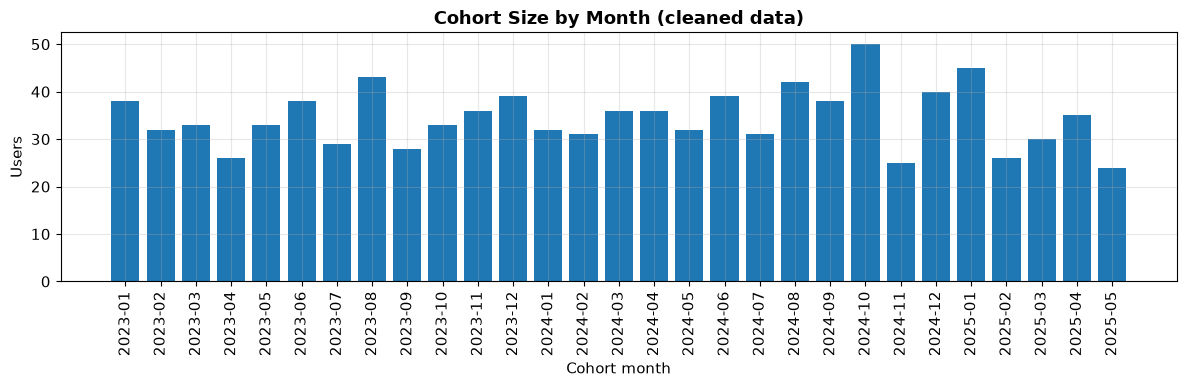

In [5]:
cohort_sizes = retention.set_index("cohort_month")["cohort_users"]

plt.figure(figsize=(12, 4))
plt.bar(cohort_sizes.index.astype(str), cohort_sizes.values, color="tab:blue")
plt.title("Cohort Size by Month (cleaned data)")
plt.xlabel("Cohort month")
plt.ylabel("Users")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

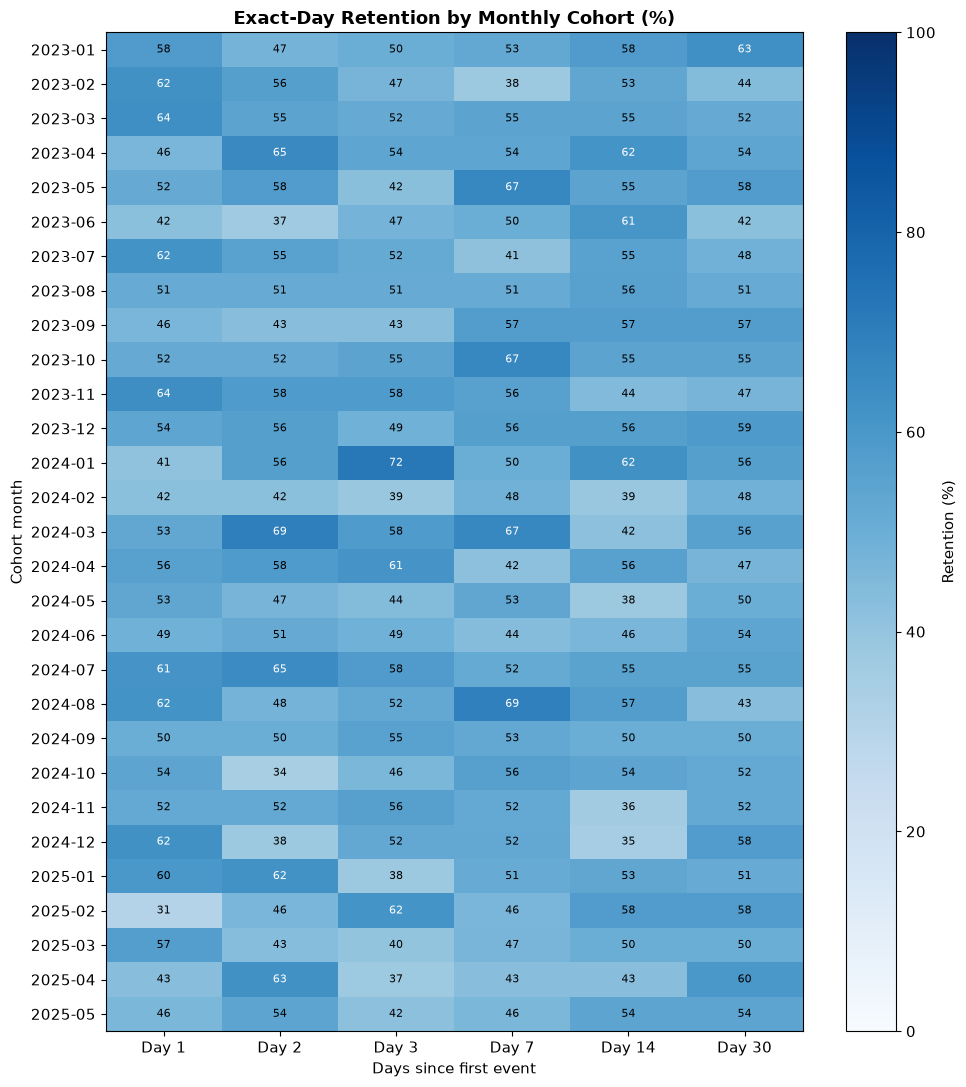

In [6]:
heatmap_data = retention.set_index("cohort_month")[retention_days]

fig, ax = plt.subplots(figsize=(10, 11))
image = ax.imshow(heatmap_data, aspect="auto", interpolation="nearest", vmin=0, vmax=100, cmap="Blues")
fig.colorbar(image, label="Retention (%)")

# value labels, so the table can be read without relying on colour alone
for row in range(heatmap_data.shape[0]):
    for col in range(heatmap_data.shape[1]):
        value = heatmap_data.iat[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if value > 60 else "black")

ax.set_xticks(range(len(retention_days)))
ax.set_xticklabels([d.replace("day", "Day ") for d in retention_days])
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index.astype(str))
ax.set_xlabel("Days since first event")
ax.set_ylabel("Cohort month")
ax.set_title("Exact-Day Retention by Monthly Cohort (%)")
ax.grid(False)
plt.tight_layout()
plt.show()

### Summary

**Average (by cohort)** treats every cohort equally and describes a typical cohort. **Weighted average (by user)** divides all returning users by all eligible users and describes a typical user. Eligible and returned users are the denominator and numerator of the weighted average.

In [7]:
retention_long = read_cohorts("exact_day_retention_monthly.csv")

totals = retention_long.groupby("day_n")[["eligible_users", "returned_users"]].sum()

retention_summary = pd.DataFrame({
    "Eligible users": totals["eligible_users"],
    "Returned users": totals["returned_users"],
    "Average (by cohort)": retention_long.groupby("day_n")["retention_pct"].mean(),
    "Weighted average (by user)": totals["returned_users"] * 100 / totals["eligible_users"],
    "Median": retention_long.groupby("day_n")["retention_pct"].median(),
    "Minimum": retention_long.groupby("day_n")["retention_pct"].min(),
    "Maximum": retention_long.groupby("day_n")["retention_pct"].max(),
}).rename(index=lambda n: f"Day {n}")

display(retention_summary.round(2))

,Eligible users,Returned users,Average (by cohort),Weighted average (by user),Median,Minimum,Maximum
day_n,,,,,,,
Day 1,1000,530,52.53,53.0,52.78,30.77,63.89
Day 2,1000,518,52.13,51.8,52.00,34.00,69.44
Day 3,1000,502,50.35,50.2,51.16,37.14,71.88
Day 7,1000,525,52.19,52.5,52.00,37.50,69.05
Day 14,1000,515,51.48,51.5,54.55,35.00,62.50
Day 30,1000,524,52.51,52.4,52.00,42.11,63.16


### Finding

On cleaned data, Exact-Day Retention is about 50% for every cohort and every analysed day: the average across cohorts is 52.53% on Day 1, 52.19% on Day 7, 51.48% on Day 14 and 52.51% on Day 30. Weighted by users, the values are almost the same (53.0%, 52.5%, 51.5% and 52.4%), because the cohorts are of similar size. For every analysed day, all 1,000 users are eligible: each user's Day 30 falls within the observation window.

Within the first 30 days, retention does not decline: a user is about as likely to be active 30 days after their first event as on the next day. In most products the retention curve falls over the first weeks, so this flat pattern is unusual and likely reflects how the synthetic data was generated. These days cover only the first month; Section 6 checks what happens after Day 30.

Individual cohorts range from about 31% to 72% depending on the day. Monthly cohorts are small (24–50 users), so the value of a single cohort can change noticeably because of a few users, and differences between individual cohorts should be interpreted with caution.

## 6. Retention Beyond Day 30

### Business Question

Does retention stay flat after Day 30?

### SQL

[04_long_horizon.sql](../sql/02_retention_cohorts/04_long_horizon.sql)

Sections 5, 7 and 8 cover the first 30 days and the open-ended Day 31+ interval. This query extends Exact-Day Retention to Day 120 for all users together, without splitting by cohort, and adds Unbounded Retention for each day (at least one event on Day N or later). A user is eligible for Day N only if this day is fully observed, as in Section 5; the number of eligible users is shown for every day, so that 0% (no events) is not confused with a day that cannot be observed. Because eligible users differ slightly between days, the same values are also shown for a fixed group: the 964 users whose whole 120-day horizon is observed.

### Results

In [8]:
long_horizon = pd.read_csv("../data/results/02_retention_cohorts/retention_long_horizon.csv")

long_horizon

,day_n,eligible_users,returned_users,exact_day_retention_pct,unbounded_retention_pct,full_horizon_users,full_horizon_exact_day_pct,full_horizon_unbounded_pct
0,1,1000,530,53.00,100.00,964,53.11,100.00
1,7,1000,525,52.50,100.00,964,52.70,100.00
2,14,1000,515,51.50,100.00,964,51.24,100.00
3,30,1000,524,52.40,100.00,964,52.18,100.00
4,45,1000,529,52.90,100.00,964,52.90,100.00
5,60,1000,525,52.50,100.00,964,52.70,100.00
6,70,1000,536,53.60,100.00,964,53.53,100.00
7,80,1000,495,49.50,98.40,964,49.79,98.34
8,90,999,314,31.43,34.13,964,31.74,34.44
9,100,988,0,0.00,0.00,964,0.00,0.00


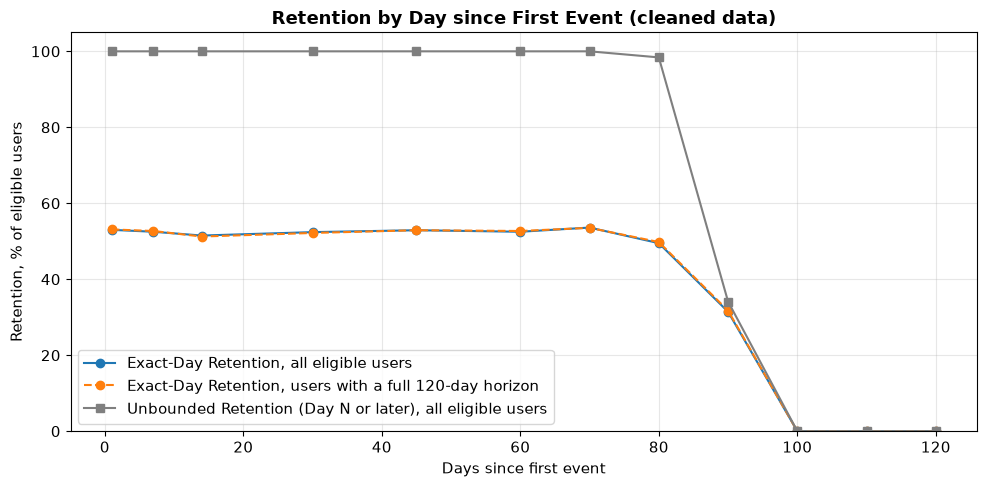

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(long_horizon["day_n"], long_horizon["exact_day_retention_pct"], marker="o", color="tab:blue",
         label="Exact-Day Retention, all eligible users")
plt.plot(long_horizon["day_n"], long_horizon["full_horizon_exact_day_pct"], marker="o", linestyle="--", color="tab:orange",
         label="Exact-Day Retention, users with a full 120-day horizon")
plt.plot(long_horizon["day_n"], long_horizon["unbounded_retention_pct"], marker="s", color="tab:gray",
         label="Unbounded Retention (Day N or later), all eligible users")

plt.title("Retention by Day since First Event (cleaned data)")
plt.xlabel("Days since first event")
plt.ylabel("Retention, % of eligible users")
plt.ylim(0, 105)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [10]:
pd.read_csv("../data/results/02_retention_cohorts/retention_last_active_day.csv")

,full_horizon_users,min_last_day,p25_last_day,median_last_day,p75_last_day,max_last_day
0,964,71,87,89.0,90,91


### Finding

Exact-Day Retention stays at 49.5–53.6% from Day 1 to Day 80 and then falls: 31.43% on Day 90 and 0% on Days 100, 110 and 120. These zeros are observed values, not missing ones: 988, 976 and 964 users are eligible on these days. The fixed group of 964 users with a fully observed 120-day horizon shows the same curve (31.74% on Day 90, 0% from Day 100), so the drop is not caused by a change in which users are eligible.

Unbounded Retention shows the same from another side: 98.4% of users still have an event on Day 80 or later, 34.13% on Day 90 or later, and 0% on Day 100 or later. For the 964 users with a full horizon, the last observed active day is Day 71–91 after the first event (median 89). This matches `05_user_behavior.ipynb`, where every user is active for 67–92 days.

So the flat retention of Section 5 holds for about the first 80 days only. After about three months, events of a user are no longer observed. This does not prove that all users left the product: the data do not distinguish real churn, how the synthetic data were generated, and how they were collected. Because every user stops at almost the same point, a property of the data generation seems more likely than real churn, but this remains a hypothesis.

## 7. Unbounded Retention

### Business Question

Do users return to the product at least once after the first 30 days?

### Definition

**D30 Unbounded Retention** measures the percentage of eligible users who return to the product at least once on Day 30 or later after their first event.

Difference from Exact-Day Retention:

- Exact-Day Retention asks whether the user was active exactly on Day N.
- Unbounded Retention asks whether the user returned at least once on Day N or later.

Only users with at least 30 days of observable time are included.

### SQL

[03_unbounded.sql](../sql/02_retention_cohorts/03_unbounded.sql)

### Results

In [11]:
unbounded = read_cohorts("unbounded_retention_monthly.csv")

display(pd.concat([unbounded.head(3), unbounded.tail(3)]))

,cohort_month,eligible_users,returned_users,d30_unbounded_retention,d30_churn
0,2023-01,38,38,100.0,0.0
1,2023-02,32,32,100.0,0.0
2,2023-03,33,33,100.0,0.0
26,2025-03,30,30,100.0,0.0
27,2025-04,35,35,100.0,0.0
28,2025-05,24,24,100.0,0.0


In [12]:
unbounded_summary = pd.DataFrame({
    "Metric": ["Average (by cohort)", "Minimum", "Maximum"],
    "D30 Unbounded Retention, %": [
        unbounded["d30_unbounded_retention"].mean(),
        unbounded["d30_unbounded_retention"].min(),
        unbounded["d30_unbounded_retention"].max()
    ]
})

display(unbounded_summary.round(2))

,Metric,"D30 Unbounded Retention, %"
0,Average (by cohort),100.0
1,Minimum,100.0
2,Maximum,100.0


### Finding

D30 Unbounded Retention is **100% in every cohort** (D30 churn is 0%): every eligible user has at least one event on Day 30 or later. The metric therefore does not distinguish cohorts.

This only means that every user is still active at some point after Day 30. It does not show that users keep returning later: Section 6 shows that unbounded retention falls to 34.13% from Day 90 and to 0% from Day 100.

### Data Limitation

D30 Unbounded Retention starts too early to see when activity stops: almost every user is still active around Day 80–90, so every user counts as retained. With a later starting day the picture is the opposite — D100 Unbounded Retention is 0% (Section 6). No activity within the observation period is also not necessarily the same as a user leaving the product. D30 Unbounded Retention and churn are therefore not used for cohort comparison.

## 8. Bracket Retention

### Business Question

Do users return to the product at least once within defined time intervals after their first event?

### Definition

**Bracket Retention** measures whether a user returned at least once during a defined time interval after their first event.

The brackets used in this analysis are:

- Day 1–7
- Day 8–14
- Day 15–30
- Day 31+

Important distinction:

- Exact-Day Retention asks whether the user was active exactly on Day N.
- Unbounded Retention asks whether the user returned at least once on Day N or later.
- Bracket Retention asks whether the user returned at least once during a specific time interval.

Only users with sufficient observation time are included in each bracket.

### SQL

[02_bracket.sql](../sql/02_retention_cohorts/02_bracket.sql)

### Results

In [13]:
bracket = read_cohorts("bracket_retention_monthly.csv")
brackets = {"day1_7": "Day 1–7", "day8_14": "Day 8–14", "day15_30": "Day 15–30", "day31_plus": "Day 31+"}

display(pd.concat([bracket.head(3), bracket.tail(3)]))

,cohort_month,day1_7,day8_14,day15_30,day31_plus
0,2023-01,89.47,100.00,100.0,100.0
1,2023-02,100.00,100.00,100.0,100.0
2,2023-03,100.00,93.94,100.0,100.0
26,2025-03,93.33,90.00,100.0,100.0
27,2025-04,100.00,100.00,100.0,100.0
28,2025-05,100.00,100.00,100.0,100.0


In [14]:
bracket_summary = pd.DataFrame({
    "Average (by cohort)": bracket[list(brackets)].mean(),
    "Median": bracket[list(brackets)].median(),
    "Minimum": bracket[list(brackets)].min(),
    "Maximum": bracket[list(brackets)].max(),
}).rename(index=brackets)

display(bracket_summary.round(2))

,Average (by cohort),Median,Minimum,Maximum
Day 1–7,97.10,97.37,89.47,100.0
Day 8–14,98.91,100.00,90.00,100.0
Day 15–30,99.91,100.00,97.50,100.0
Day 31+,100.00,100.00,100.00,100.0


### Finding

Bracket Retention is close to 100% in every cohort: on average 97.10% for Day 1–7, 98.91% for Day 8–14, 99.91% for Day 15–30 and 100% for Day 31+, with a minimum of 89.47% across all cohorts and brackets.

This follows from the Exact-Day Retention of about 50% in the first 30 days. If a user is active on about half of the days, the probability of at least one active day in a 7-day window is close to 100%, so almost every user "returns" in every bracket.

Day 31+ is open-ended: it counts any activity on Day 31 or later, so it is 100% even though activity stops after about three months (Section 6). These are separate time intervals, and a user can be inactive in one bracket and return in a later one. The difference between bracket averages should not be interpreted as retention improving over time.

### Data Limitation

Because Bracket Retention averages 97–100% across cohorts and is at least 89% in every cohort, it does not provide meaningful differentiation between cohorts in this dataset. No cohort chart is shown for it; the summary table is sufficient.

## 9. Key Findings

- **The anomaly distorts cohorts.** On all data, the June and July 2023 cohorts contain 405 and 117 users with 7–9% Day 7 retention, and later cohorts are almost empty. The anomalous sessions move users into these cohorts long before they sign up. On cleaned data, cohort sizes (24–50 users) match monthly sign-ups.
- **Retention is flat at about 50% in the first 30 days.** On cleaned data, average Exact-Day Retention is 52.53% on Day 1, 52.19% on Day 7, 51.48% on Day 14 and 52.51% on Day 30 (almost the same when weighted by users).
- **After about three months, activity is no longer observed.** Exact-Day Retention stays at 49.5–53.6% until Day 80, then falls to 31.43% on Day 90 and 0% from Day 100, while 964–988 users are still eligible. No user has any event 100 or more days after their first event. The data do not show whether this is real churn, a property of the synthetic data or of the observation process.
- **Longer-window metrics do not differentiate cohorts.** D30 Unbounded Retention is 100% (D30 churn 0%) in every cohort, and Bracket Retention averages 97–100% across cohorts (at least 89% in every cohort); both only show that users are still active at some point after Day 30.

## 10. Product Interpretation

After the anomalous sessions are removed, the cohorts behave almost identically: about half of a cohort is active on any given day during the first 30 days (and until about Day 80), and practically all users return within any week. Then activity stops: for the 964 users with a fully observed 120-day horizon, the last observed active day is Day 71–91 after the first event.

Such a pattern is unusual for a real product, where retention typically decreases gradually over the first weeks and some users never return. A flat curve followed by a stop at the same point for all users is more likely a property of the synthetic dataset than evidence of exceptional retention followed by mass churn, although the data alone cannot establish the cause. The main analytical value of this notebook is therefore methodological: the cohort differences visible on raw data come from the data anomaly and from small, unweighted daily cohorts, and they disappear once both issues are addressed.

Exact-Day Retention, D30 Unbounded Retention and Bracket Retention provide limited differentiation between cohorts in this dataset. Further analysis should focus on purchase-based retention (`03_purchase_retention.ipynb`), engagement intensity and segmentation by acquisition channel.

## 11. Next Questions

1. Does purchase retention (`03_purchase_retention.ipynb`) show more variation between cohorts than activity-based retention?
2. Would cohorts defined by sign-up date (`users.signup_time`) instead of first event show the same pattern?
3. Do retention patterns differ by acquisition channel or country, where segments may be larger than monthly cohorts?
4. Why does activity stop about three months after the first event for every user: is it churn, how the data were generated, or how they were collected?

## 12. Limitations

- The dataset is synthetic: retention is flat at about 50% until about Day 80, and no activity is observed after Day 91 for any user. The data do not distinguish real churn from properties of the data generation or observation process.
- Monthly cohorts are small (24–50 users), so the value of a single cohort can change noticeably because of a few users.
- Exact-Day Retention measures activity on specific days and should not be interpreted as cumulative retention.
- The cohort is defined by the first event in `events_clean`; 10 users still have their first event on a date before their sign-up date (149 if exact times are compared, mostly events a few hours before sign-up on the same day).
- The analysis is observational and does not establish causal relationships.

## 13. References

Retention and cohort definitions follow Amplitude's product analytics materials:

- Amplitude — [Retention Analytics: Retention Analytics For Stopping Churn In Its Tracks](https://amplitude.com/guides/retention-analytics) (N-day, unbounded and bracket retention)
- Amplitude — [The Complete Guide to Cohort Analysis](https://amplitude.com/explore/analytics/cohort-analysis)
- Dataset — [adisomani/duckdb_product_analytics_tutorial](https://github.com/adisomani/duckdb_product_analytics_tutorial)